# Preliminary Data Exploration

This notebook explores the **xBD-S12** dataset with a focus on the **4 flood events** (`peril == 'flood'`):
- `hurricane-florence`
- `hurricane-harvey`
- `midwest-flooding`
- `nepal-flooding`

- **Train (3 events)**: `hurricane-florence`, `hurricane-harvey`, `midwest-flooding` (1,513 tiles)
- **Test (1 event)**: `nepal-flooding` (619 tiles)

In [10]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

#repo_root = Path.cwd()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.constants import (
    CLASSES_ORIGINAL,
    COLORS,
    COLORS_ORIGINAL,
    FLOOD_DISASTERS,
    FLOOD_TEST_DISASTERS,
    FLOOD_TRAIN_DISASTERS,
    XBD_S12_PATH,
)
from src.data.metadata import load_metadata

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Load Metadata & Compare Flood Events vs. All Disasters

In [12]:
gdf = load_metadata()
print(f"Total count in xBD-S12: {len(gdf):,}")
print(f"Columns ({len(gdf.columns)}): {list(gdf.columns)}")
gdf.head(3)

Total count in xBD-S12: 10,315
Columns (34): ['disaster', 'disaster_type', 'peril', 'xbd_tier', 'event_split', 'best_utm', 'N_intact', 'N_minor', 'N_major', 'N_destroyed', 'N_unclassified', 'N_total', 'xbd_date_pre', 'xbd_date_post', 'xbd_catalog_id_pre', 'xbd_catalog_id_post', 'xbd_sensor_pre', 'xbd_sensor_post', 'xbd_perc_nan_pre', 'xbd_perc_nan_post', 's2_mgrs_tile', 's2_date_pre', 's2_date_post', 's2_cs_pre', 's2_cs_post', 's1_date_pre', 's1_date_post', 's1_orbit_pre', 's1_orbit_post', 's1_direction_pre', 's1_direction_post', 's1_ids_pre', 's1_ids_post', 'geometry']


,disaster,disaster_type,peril,xbd_tier,event_split,best_utm,N_intact,N_minor,N_major,N_destroyed,...,s2_cs_post,s1_date_pre,s1_date_post,s1_orbit_pre,s1_orbit_post,s1_direction_pre,s1_direction_post,s1_ids_pre,s1_ids_post,geometry
xbd_uid,,,,,,,,,,,,,,,,,,,,,
guatemala-volcano_00000000,guatemala-volcano,volcano,volcano,train,test,EPSG:32615,10,0,0,0,...,0.832290,2018-02-06,2018-06-24,26,26,DESCENDING,DESCENDING,S1B_IW_GRDH_1SDV_20180206T115329_20180206T1153...,S1A_IW_GRDH_1SDV_20180624T115419_20180624T1154...,"POLYGON ((-90.8132 14.39158, -90.81325 14.3870..."
guatemala-volcano_00000001,guatemala-volcano,volcano,volcano,train,test,EPSG:32615,0,4,0,0,...,0.858505,2018-02-06,2018-06-24,26,26,DESCENDING,DESCENDING,S1B_IW_GRDH_1SDV_20180206T115329_20180206T1153...,S1A_IW_GRDH_1SDV_20180624T115419_20180624T1154...,"POLYGON ((-90.81316 14.39612, -90.8132 14.3915..."
guatemala-volcano_00000002,guatemala-volcano,volcano,volcano,train,test,EPSG:32615,0,0,0,1,...,0.884884,2018-02-06,2018-06-24,26,26,DESCENDING,DESCENDING,S1B_IW_GRDH_1SDV_20180206T115329_20180206T1153...,S1A_IW_GRDH_1SDV_20180624T115419_20180624T1154...,"POLYGON ((-90.83303 14.42975, -90.83308 14.425..."


In [13]:
peril_summary = (
    gdf.groupby(["peril", "disaster"])
    .agg(
        n_tiles=("N_total", "count"),
        tiles_with_buildings=("N_total", lambda s: (s > 0).sum()),
        total_buildings=("N_total", "sum"),
        intact=("N_intact", "sum"),
        minor=("N_minor", "sum"),
        major=("N_major", "sum"),
        destroyed=("N_destroyed", "sum"),
        unclassified=("N_unclassified", "sum"),
    )
)
peril_summary["damaged_total"] = peril_summary["minor"] + peril_summary["major"] + peril_summary["destroyed"]
peril_summary["pct_damaged"] = (peril_summary["damaged_total"] / peril_summary["total_buildings"].clip(lower=1) * 100).round(1)
peril_summary

n_tiles  tiles_with_buildings  \
peril      disaster                                             
earthquake mexico-earthquake        193                   193   
           palu-tsunami             196                   193   
           sunda-tsunami            148                   105   
flood      hurricane-florence       546                   520   
           hurricane-harvey         522                   492   
           midwest-flooding         445                   392   
           nepal-flooding           619                   576   
storm      hurricane-matthew        405                   379   
           hurricane-michael        550                   534   
volcano    guatemala-volcano         28                    27   
           lower-puna-volcano       291                   183   
wildfire   pinery-bushfire         1845                   479   
           portugal-wildfire       1869                   975   
           santa-rosa-wildfire      377                   368   
           socal-fire              1403                   700   
           woolsey-fire             878                   402   

                                total_buildings  intact  minor  major  \
peril      disaster                                                     
earthquake mexico-earthquake              51473   51084    221     54   
           palu-tsunami                   55789   46796      1   1178   
           sunda-tsunami                  16947   14078      0    100   
flood      hurricane-florence             11548    8466    232   1949   
           hurricane-harvey               37955   18638   4510  13378   
           midwest-flooding               13896   12819    246    193   
           nepal-flooding                 43265   31225   5134   4721   
storm      hurricane-matthew              23964    4058  12331   2717   
           hurricane-michael              35501   22692   8292   2919   
volcano    guatemala-volcano                991     731     26     23   
           lower-puna-volcano              3410    2277     49     26   
wildfire   pinery-bushfire                 5961    5027     82     99   
           portugal-wildfire              23413   20787    176    296   
           santa-rosa-wildfire            21955   15843    121     95   
           socal-fire                     18969   15697    136    110   
           woolsey-fire                    7015    4638    189    126   

                                destroyed  unclassified  damaged_total  \
peril      disaster                                                      
earthquake mexico-earthquake            3           111            278   
           palu-tsunami              7203           611           8382   
           sunda-tsunami              179          2590            279   
flood      hurricane-florence          81           820           2262   
           hurricane-harvey           848           581          18736   
           midwest-flooding           165           473            604   
           nepal-flooding             502          1683          10357   
storm      hurricane-matthew         3524          1334          18572   
           hurricane-michael         1225           373          12436   
volcano    guatemala-volcano           33           178             82   
           lower-puna-volcano         504           554            579   
wildfire   pinery-bushfire            229           524            410   
           portugal-wildfire         1090          1064           1562   
           santa-rosa-wildfire       5810            86           6026   
           socal-fire                2333           693           2579   
           woolsey-fire              1876           186           2191   

                                pct_damaged  
peril      disaster                          
earthquake mexico-earthquake            0.5  
           palu-tsunami                15.0  
           sunda-tsunami     

## 2. Flood Event exploration

In [14]:
flood_df = gdf[gdf["disaster"].isin(FLOOD_DISASTERS)].copy()
flood_df["N_damaged"] = flood_df["N_minor"] + flood_df["N_major"] + flood_df["N_destroyed"]
flood_df["has_buildings"] = flood_df["N_total"] > 0

flood_stats = (
    flood_df.groupby("disaster")
    .agg(
        n_tiles=("N_total", "count"),
        empty_tiles=("has_buildings", lambda s: (~s).sum()),
        non_empty_tiles=("has_buildings", "sum"),
        N_total=("N_total", "sum"),
        N_intact=("N_intact", "sum"),
        N_minor=("N_minor", "sum"),
        N_major=("N_major", "sum"),
        N_destroyed=("N_destroyed", "sum"),
        N_damaged=("N_damaged", "sum"),
        N_unclassified=("N_unclassified", "sum"),
    )
)
flood_stats["pct_empty_tiles"] = (flood_stats["empty_tiles"] / flood_stats["n_tiles"] * 100).round(1)
flood_stats["pct_damaged_buildings"] = (flood_stats["N_damaged"] / flood_stats["N_total"] * 100).round(1)
flood_stats

,n_tiles,empty_tiles,non_empty_tiles,N_total,N_intact,N_minor,N_major,N_destroyed,N_damaged,N_unclassified,pct_empty_tiles,pct_damaged_buildings
disaster,,,,,,,,,,,,
hurricane-florence,546,26,520,11548,8466,232,1949,81,2262,820,4.8,19.6
hurricane-harvey,522,30,492,37955,18638,4510,13378,848,18736,581,5.7,49.4
midwest-flooding,445,53,392,13896,12819,246,193,165,604,473,11.9,4.3
nepal-flooding,619,43,576,43265,31225,5134,4721,502,10357,1683,6.9,23.9


## 3. Visualizing Flood Image Patches & Testing Baseline Model

First, let's visualize pre- and post-disaster **Sentinel-1 (VV)** and **Sentinel-2 (RGB TCI)** patches for each of the 4 flood events directly from `data/xbd_s12/`.

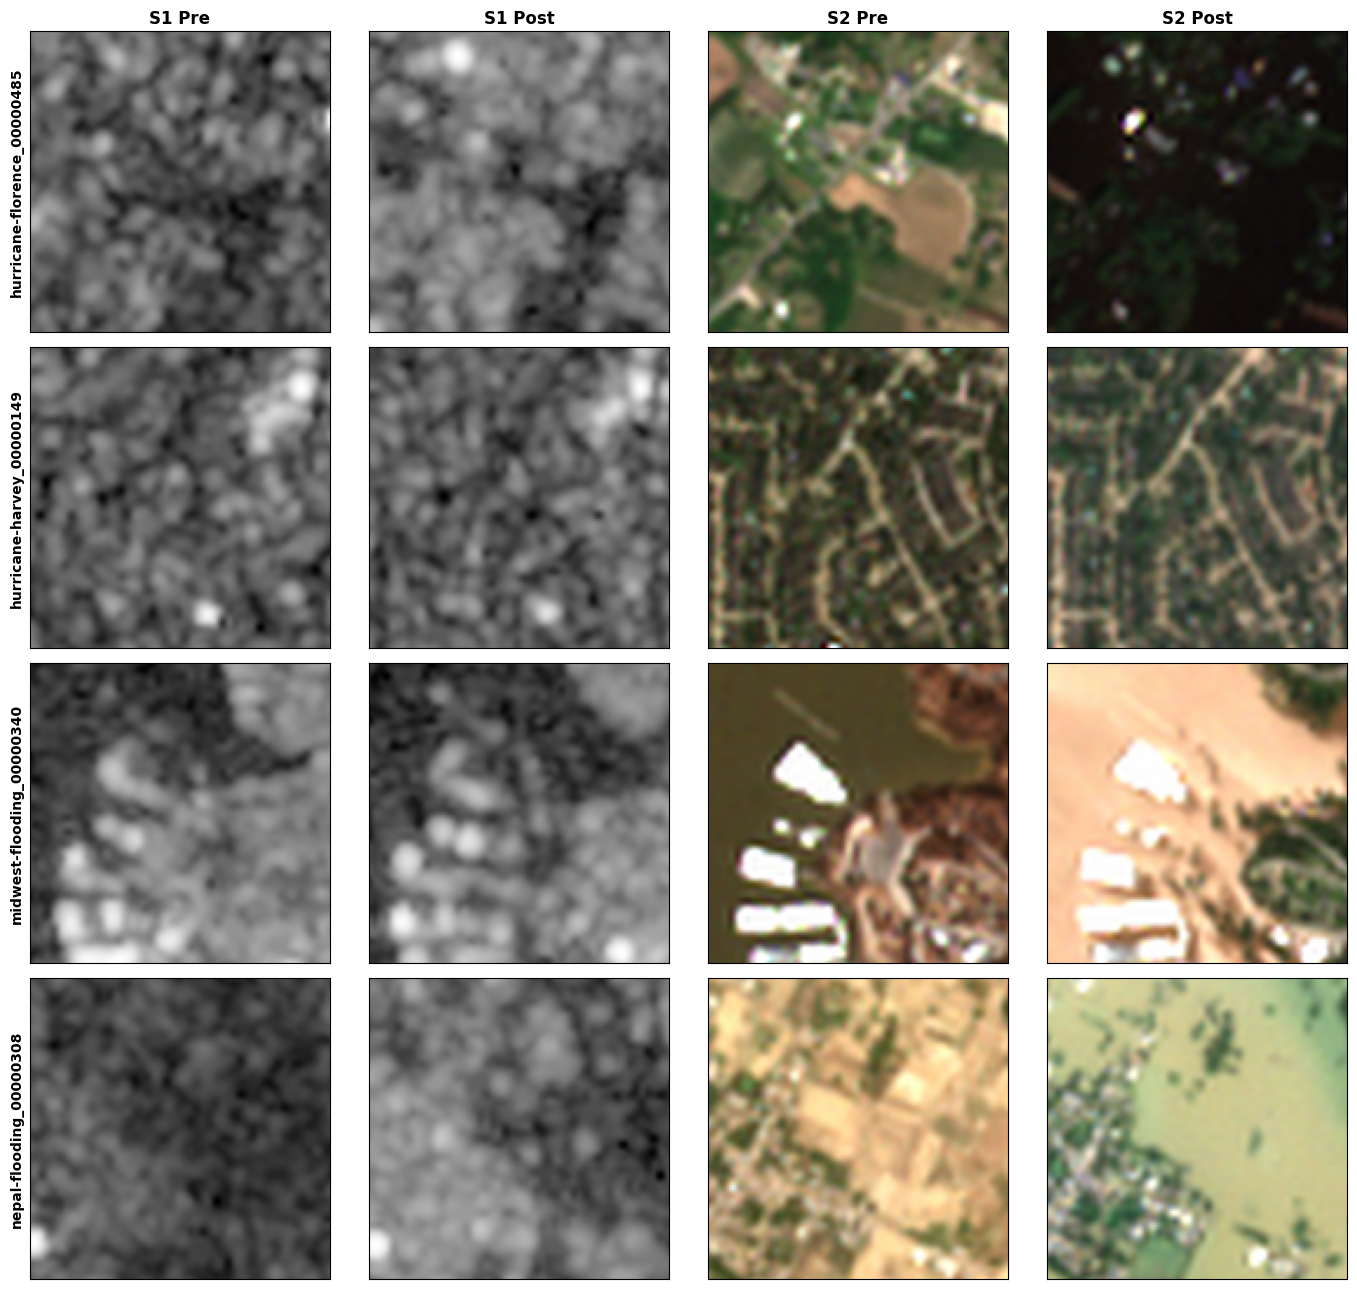

In [17]:
if (XBD_S12_PATH / "s1").exists() and (XBD_S12_PATH / "s2_tci").exists():
    import rioxarray as rxr

    fig, axes = plt.subplots(4, 4, figsize=(14, 13))
    for row_idx, disaster in enumerate(FLOOD_DISASTERS):
        # Pick most damaged tile for each disaster
        sub = flood_df[flood_df["disaster"] == disaster].sort_values("N_damaged", ascending=False)
        uid = sub.index[0]
        n_dmg = int(sub.iloc[0]["N_damaged"])
        n_tot = int(sub.iloc[0]["N_total"])

        s1_pre = rxr.open_rasterio(XBD_S12_PATH / "s1" / f"{uid}_pre_disaster_s1.tif").values[0]
        s1_post = rxr.open_rasterio(XBD_S12_PATH / "s1" / f"{uid}_post_disaster_s1.tif").values[0]
        s2_pre = rxr.open_rasterio(XBD_S12_PATH / "s2_tci" / f"{uid}_pre_disaster_s2_tci.tif").values.transpose(1, 2, 0)
        s2_post = rxr.open_rasterio(XBD_S12_PATH / "s2_tci" / f"{uid}_post_disaster_s2_tci.tif").values.transpose(1, 2, 0)

        axes[row_idx, 0].imshow(s1_pre, cmap="gray")
        axes[row_idx, 1].imshow(s1_post, cmap="gray")
        axes[row_idx, 2].imshow(s2_pre)
        axes[row_idx, 3].imshow(s2_post)

        axes[row_idx, 0].set_ylabel(f"{uid}", fontsize=10, fontweight="bold")
        if row_idx == 0:
            axes[row_idx, 0].set_title("S1 Pre", fontweight="bold")
            axes[row_idx, 1].set_title("S1 Post", fontweight="bold")
            axes[row_idx, 2].set_title("S2 Pre", fontweight="bold")
            axes[row_idx, 3].set_title("S2 Post", fontweight="bold")
        for col_idx in range(4):
            axes[row_idx, col_idx].set_xticks([])
            axes[row_idx, col_idx].set_yticks([])

    plt.tight_layout()
    plt.show()
else:
    print(f"Sentinel images not found at {XBD_S12_PATH}.")